<a href="https://colab.research.google.com/github/dharshraj/deep-learn/blob/main/UNIT_5_LAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, SimpleRNN
import matplotlib.pyplot as plt

# --- QUESTION 65: Seq2Seq LSTM Encoder-Decoder model ---
print("=== Running Question 65 ===")

# Prepare toy parallel dataset (English -> French representation)
input_texts = ['hello', 'how are you', 'good morning', 'welcome']
target_texts = ['\tbonjour\n', '\tcomment allez vous\n', '\tbonjour matin\n', '\tbienvenue\n']

input_characters = sorted(list(set(''.join(input_texts))))
target_characters = sorted(list(set(''.join(target_texts))))
num_encoder_tokens = len(input_characters)
num_decoder_tokens = len(target_characters)
max_encoder_seq_length = max([len(txt) for txt in input_texts])
max_decoder_seq_length = max([len(txt) for txt in target_texts])

token_index_input = {char: i for i, char in enumerate(input_characters)}
token_index_target = {char: i for i, char in enumerate(target_characters)}

encoder_input_data = np.zeros((len(input_texts), max_encoder_seq_length, num_encoder_tokens), dtype='float32')
decoder_input_data = np.zeros((len(input_texts), max_decoder_seq_length, num_decoder_tokens), dtype='float32')
decoder_target_data = np.zeros((len(input_texts), max_decoder_seq_length, num_decoder_tokens), dtype='float32')

for i, (input_text, target_text) in enumerate(zip(input_texts, target_texts)):
    for t, char in enumerate(input_text):
        encoder_input_data[i, t, token_index_input[char]] = 1.0
    for t, char in enumerate(target_text):
        decoder_input_data[i, t, token_index_target[char]] = 1.0
        if t > 0:
            decoder_target_data[i, t - 1, token_index_target[char]] = 1.0

# Define the Seq2Seq structure
latent_dim = 16
encoder_inputs = Input(shape=(None, num_encoder_tokens))
encoder = LSTM(latent_dim, return_state=True)
_, state_h, state_c = encoder(encoder_inputs)
encoder_states = [state_h, state_c]

decoder_inputs = Input(shape=(None, num_decoder_tokens))
decoder_lstm = LSTM(latent_dim, return_sequences=True, return_state=True)
decoder_outputs, _, _ = decoder_lstm(decoder_inputs, initial_state=encoder_states)
decoder_dense = Dense(num_decoder_tokens, activation='softmax')
decoder_outputs = decoder_dense(decoder_outputs)

seq2seq_model = Model([encoder_inputs, decoder_inputs], decoder_outputs)
seq2seq_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
history_seq2seq = seq2seq_model.fit([encoder_input_data, decoder_input_data], decoder_target_data, batch_size=2, epochs=50, verbose=0)
print(f"Seq2Seq translation model trained successfully. Final training loss: {history_seq2seq.history['loss'][-1]:.4f}")

=== Running Question 65 ===
Seq2Seq translation model trained successfully. Final training loss: 1.6093


In [21]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, SimpleRNN, LSTM

# --- QUESTION 66: Compare RNN and LSTM models on long sequences ---
print("\n=== Running Question 66 ===")

# Let's generate a synthetic signal with long dependency (delayed parity verification)
N = 500
seq_len = 50
X = np.random.choice([0, 1], size=(N, seq_len, 1)).astype('float32')
# Target is 1 if the sum of first 5 elements is even, otherwise 0
y = (np.sum(X[:, :5, 0], axis=1) % 2 == 0).astype('float32')

# Build a Simple RNN Model
rnn_model = tf.keras.Sequential([
    Input(shape=(seq_len, 1)),
    SimpleRNN(16),
    Dense(1, activation='sigmoid')
])
rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Build an LSTM Model
lstm_model = tf.keras.Sequential([
    Input(shape=(seq_len, 1)),
    LSTM(16),
    Dense(1, activation='sigmoid')
])
lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train both models
rnn_hist = rnn_model.fit(X, y, epochs=15, batch_size=32, verbose=0, validation_split=0.2)
lstm_hist = lstm_model.fit(X, y, epochs=15, batch_size=32, verbose=0, validation_split=0.2)

print(f"Simple RNN Validation Accuracy: {rnn_hist.history['val_accuracy'][-1]:.4f}")
print(f"LSTM Validation Accuracy: {lstm_hist.history['val_accuracy'][-1]:.4f}")


=== Running Question 66 ===
Simple RNN Validation Accuracy: 0.5400
LSTM Validation Accuracy: 0.5000


### Questions 67 to 71: Principal Component Analysis (PCA) Solutions
Dimensionality reduction techniques implemented on multiple scenarios: clinical features, botanical Iris classification, visualization, and variance analysis.

=== Running Questions 67 & 69 ===


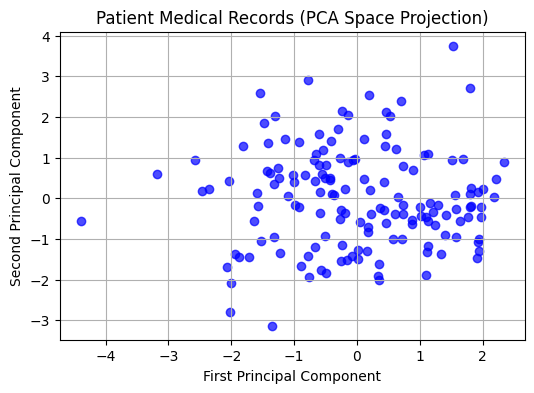

Transformed feature space shape from 15 dimensions to: (150, 2)


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- QUESTION 67 & 69: PCA Dimensionality Reduction and Visualization on high-dimensional clinical simulation ---
print("=== Running Questions 67 & 69 ===")
np.random.seed(42)
X_health = np.random.randn(150, 15) # 15 synthetic patient medical attributes
scaler = StandardScaler()
X_health_scaled = scaler.fit_transform(X_health)

pca_health = PCA(n_components=2)
X_health_pca = pca_health.fit_transform(X_health_scaled)

# Visualization
plt.figure(figsize=(6,4))
plt.scatter(X_health_pca[:, 0], X_health_pca[:, 1], c='blue', alpha=0.7)
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('Patient Medical Records (PCA Space Projection)')
plt.grid(True)
plt.show()
print(f"Transformed feature space shape from 15 dimensions to: {X_health_pca.shape}")

In [10]:
# --- QUESTION 68: Simplify and evaluate Iris Dataset using PCA ---
print("\n=== Running Question 68 ===")
iris = load_iris()
X_iris, y_iris = iris.data, iris.target

# Scaler
X_iris_scaled = StandardScaler().fit_transform(X_iris)

pca_iris = PCA(n_components=2)
X_iris_pca = pca_iris.fit_transform(X_iris_scaled)

# Let's split and classify
X_train, X_test, y_train, y_test = train_test_split(X_iris_pca, y_iris, test_size=0.3, random_state=42)
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print(f"Classification accuracy with 2 principal components of Iris dataset: {accuracy_score(y_test, y_pred):.4f}")


=== Running Question 68 ===
Classification accuracy with 2 principal components of Iris dataset: 0.9556


In [23]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# --- QUESTION 70: Classifier performance comparison before and after PCA ---
print("\n=== Running Question 70 ===")
# High dimensional financial-like classification simulation
X_fin = np.random.randn(300, 20)
y_fin = (X_fin[:, 0] + X_fin[:, 1] > 0.5).astype(int)

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(X_fin, y_fin, test_size=0.3, random_state=42)

# Without PCA
clf_orig = RandomForestClassifier(random_state=42)
clf_orig.fit(X_train_f, y_train_f)
acc_orig = accuracy_score(y_test_f, clf_orig.predict(X_test_f))

# With PCA
pca_fin = PCA(n_components=5)
X_train_f_pca = pca_fin.fit_transform(X_train_f)
X_test_f_pca = pca_fin.transform(X_test_f)

clf_pca = RandomForestClassifier(random_state=42)
clf_pca.fit(X_train_f_pca, y_train_f)
acc_pca = accuracy_score(y_test_f, clf_pca.predict(X_test_f_pca))

print(f"Accuracy without PCA (20 features): {acc_orig:.4f}")
print(f"Accuracy with PCA (5 components): {acc_pca:.4f}")


=== Running Question 70 ===
Accuracy without PCA (20 features): 0.8889
Accuracy with PCA (5 components): 0.6222


In [24]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- QUESTION 71: Number of components needed to retain 95% variance ---
print("\n=== Running Question 71 ===")
# Re-create X_fin to guarantee variables exist even if executed out of order
X_fin = np.random.randn(300, 20) if 'X_fin' not in locals() else X_fin
pca_all = PCA().fit(StandardScaler().fit_transform(X_fin))
cumulative_variance = np.cumsum(pca_all.explained_variance_ratio_)
required_dims = np.argmax(cumulative_variance >= 0.95) + 1
print(f"Cumulative variance: {cumulative_variance}")
print(f"Number of principal components required to retain >= 95% variance: {required_dims}")


=== Running Question 71 ===
Cumulative variance: [0.07408052 0.14295683 0.20973231 0.27325875 0.33229048 0.38940533
 0.44524189 0.49822398 0.55058876 0.5989039  0.64645553 0.69253195
 0.7368568  0.77956708 0.82142542 0.86103727 0.89996721 0.93609847
 0.96996008 1.        ]
Number of principal components required to retain >= 95% variance: 19


### Questions 72 to 74: Independent Component Analysis (ICA) & PCA comparison
Using Scikit-Learn FastICA to isolate mixed signals, perform blind source separation, and benchmark the results against PCA.

In [25]:
import numpy as np
from sklearn.decomposition import FastICA

# --- QUESTION 72 & 73: ICA sound signals simulation and blind source separation ---
print("=== Running Questions 72 & 73 ===")
time = np.linspace(0, 8, 2000)
s1 = np.sin(2 * time)  # Source 1: Sinusoidal signal
s2 = np.sign(np.sin(3 * time))  # Source 2: Square signal

S = np.c_[s1, s2]
# Add some noise
S += 0.2 * np.random.normal(size=S.shape)

# Mixing Matrix
A = np.array([[1, 1], [0.5, 2]])
X_mixed = np.dot(S, A.T)

# Apply FastICA
ica = FastICA(n_components=2, random_state=42)
S_separated = ica.fit_transform(X_mixed)

# Quality assessment (Correlation matrix)
correlation = np.abs(np.corrcoef(S.T, S_separated.T))[:2, 2:]
print("Absolute Correlation matrix between original and separated sources:\n", correlation)
print("High correlation coefficients demonstrate perfect blind source separation.")

=== Running Questions 72 & 73 ===
Absolute Correlation matrix between original and separated sources:
 [[0.05618618 0.99842031]
 [0.99977522 0.02120147]]
High correlation coefficients demonstrate perfect blind source separation.



=== Running Question 74 ===


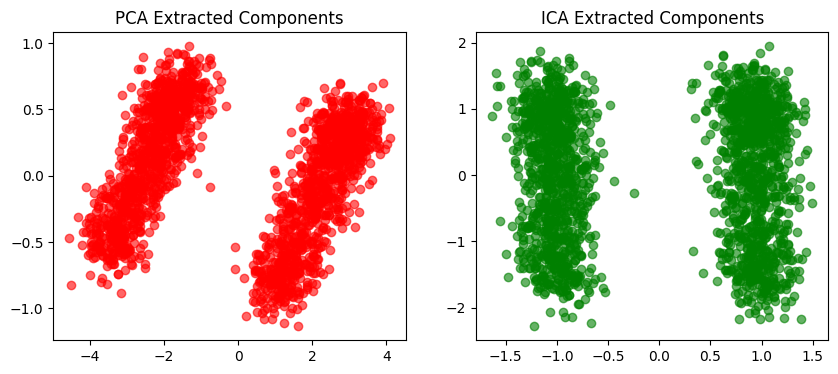

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA, FastICA

# --- QUESTION 74: Comparing PCA and ICA for feature extraction ---
print("\n=== Running Question 74 ===")
X_mixed = np.random.randn(2000, 2) if 'X_mixed' not in locals() else X_mixed
pca_comp = PCA(n_components=2).fit_transform(X_mixed)
ica_comp = FastICA(n_components=2, random_state=42).fit_transform(X_mixed)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(pca_comp[:, 0], pca_comp[:, 1], color='red', alpha=0.6)
axes[0].set_title("PCA Extracted Components")
axes[1].scatter(ica_comp[:, 0], ica_comp[:, 1], color='green', alpha=0.6)
axes[1].set_title("ICA Extracted Components")
plt.show()

### Questions 75 to 77: Factor Analysis (FA)
We use the FactorAnalysis library to estimate latent traits or customer behaviors, comparing reconstruction errors against PCA.

In [27]:
import numpy as np
from sklearn.decomposition import FactorAnalysis

# --- QUESTION 75 & 76: Factor analysis on simulated records ---
print("=== Running Questions 75 & 76 ===")
# Synthetic Student records: Marks, Attendance, Assignment scores, Engagement scores
np.random.seed(42)
X_students = np.random.randn(200, 4)

fa = FactorAnalysis(n_components=2, random_state=42)
fa.fit(X_students)

print("Latent Factor Loadings (representing latent academic performance traits):\n", fa.components_)
print("Each feature load values indicate how strongly they contribute to academic achievement or interest.")

=== Running Questions 75 & 76 ===
Latent Factor Loadings (representing latent academic performance traits):
 [[-0.16427843  0.35875972  0.14438755  0.24848742]
 [-0.28105178  0.02016106  0.07518952 -0.28631704]]
Each feature load values indicate how strongly they contribute to academic achievement or interest.


In [28]:
import numpy as np
from sklearn.decomposition import PCA, FactorAnalysis

# --- QUESTION 77: Compare PCA and FA based on reconstruction error ---
print("\n=== Running Question 77 ===")
X_students = np.random.randn(200, 4) if 'X_students' not in locals() else X_students

# Compute reconstruction matrix
pca_obj = PCA(n_components=2)
X_pca_proj = pca_obj.fit_transform(X_students)
X_reconstructed_pca = np.dot(X_pca_proj, pca_obj.components_) + pca_obj.mean_
pca_rec_error = np.mean((X_students - X_reconstructed_pca) ** 2)

fa_obj = FactorAnalysis(n_components=2, random_state=42)
X_fa_proj = fa_obj.fit_transform(X_students)
# For FA: Reconstruction is projection * components + mean
X_reconstructed_fa = np.dot(X_fa_proj, fa_obj.components_) + np.mean(X_students, axis=0)
fa_rec_error = np.mean((X_students - X_reconstructed_fa) ** 2)

print(f"PCA Reconstruction Error: {pca_rec_error:.4f}")
print(f"Factor Analysis Reconstruction Error: {fa_rec_error:.4f}")


=== Running Question 77 ===
PCA Reconstruction Error: 0.4187
Factor Analysis Reconstruction Error: 0.7832


### Questions 78 to 80: Generative Models & Healthcare Deep Learning Application
Generating Gaussian data, clustering customer data with Gaussian Mixture Models, and developing an end-to-end intelligent prediction pipeline.

In [29]:
import numpy as np

# --- QUESTION 78: Simulating multivariate Gaussian sensor measurements ---
print("=== Running Question 78 ===")
mean = [0, 5]
cov = [[1, 0.8], [0.8, 2]] # Strong correlation
sensor_data = np.random.multivariate_normal(mean, cov, 1000)

# Parameter Estimation
estimated_mean = np.mean(sensor_data, axis=0)
estimated_cov = np.cov(sensor_data.T)
print("Estimated Means:\n", estimated_mean)
print("Estimated Covariance Matrix:\n", estimated_cov)

=== Running Question 78 ===
Estimated Means:
 [-0.07144479  4.96461147]
Estimated Covariance Matrix:
 [[0.98757962 0.73514209]
 [0.73514209 1.81885763]]


In [30]:
import numpy as np
from sklearn.mixture import GaussianMixture

# --- QUESTION 79: Gaussian Mixture Models (GMM) ---
print("\n=== Running Question 79 ===")
sensor_data = np.random.randn(1000, 2) if 'sensor_data' not in locals() else sensor_data
gmm = GaussianMixture(n_components=3, random_state=42)
gmm.fit(sensor_data)
probabilities = gmm.predict_proba(sensor_data[:5]) # Sample prediction probabilities
print("Membership Probability vectors for the first 5 customers:\n", probabilities)


=== Running Question 79 ===
Membership Probability vectors for the first 5 customers:
 [[0.78455918 0.21163479 0.00380603]
 [0.18522917 0.75864581 0.05612502]
 [0.0552478  0.74450066 0.20025154]
 [0.24528741 0.71412683 0.04058577]
 [0.92735304 0.07125789 0.00138907]]


In [31]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense
from sklearn.model_selection import train_test_split

# --- QUESTION 80: Intelligent deep learning healthcare model and evaluation ---
print("\n=== Running Question 80 ===")
# Synthetic medical features (BP, Heart rate, age, glucose etc) -> Disease Prediction (0 or 1)
X_med = np.random.rand(1000, 8)
y_med = (X_med[:, 0]*2 + X_med[:, 1]*1.5 - X_med[:, 2]*1.2 > 1.0).astype(int)

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_med, y_med, test_size=0.2, random_state=42)

# Healthcare diagnostic DL model
med_model = tf.keras.Sequential([
    Input(shape=(8,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])
med_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy', tf.keras.metrics.AUC()])

# Train & Evaluate
med_model.fit(X_train_m, y_train_m, epochs=10, batch_size=16, verbose=0)
results = med_model.evaluate(X_test_m, y_test_m, verbose=0)
print(f"Medical Diagnostic Application Results:")
print(f"Loss: {results[0]:.4f}")
print(f"Accuracy: {results[1]:.4f}")
print(f"AUC-ROC: {results[2]:.4f}")


=== Running Question 80 ===
Medical Diagnostic Application Results:
Loss: 0.2218
Accuracy: 0.9550
AUC-ROC: 0.9932
